# **Question 4.6.1**
**What happens if we change the dropout probabilities of the first and second layers? Specifically, what occurs if we swap these two layers? Design an experiment to answer these questions, quantitatively describe the results, and summarize the qualitative conclusions.**

Swapping the dropout probabilities between two layers can lead to worse results. Increasing the dropout probability also increases the loss and reduces training prediction accuracy, and adjusting the dropout probability of the first layer has a greater impact than that of the second layer.

In [43]:
from d2l import torch as d2l
import torch
from torch import nn

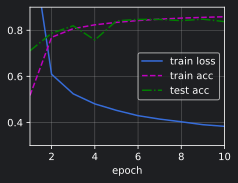

In [2]:
num_epochs, lr, batch_size = 10, 0.5, 256
dropout1, dropout2= 0.5, 0.2
loss = nn.CrossEntropyLoss(reduction='none')
train_iter, test_iter = d2l.load_data_fashion_mnist(batch_size, root='../../data')

net = nn.Sequential(
    nn.Flatten(),
    nn.Linear(784, 256),
    nn.ReLU(),
    # Add a dropout layer after the first fully connected layer
    nn.Dropout(dropout1),
    nn.Linear(256, 256),
    nn.ReLU(),
    # Add a dropout layer after the second fully connected layer
    nn.Dropout(dropout2),
    nn.Linear(256, 10),
)

def init_weights(m):
    if isinstance(m, nn.Linear):
        nn.init.normal_(m.weight, std=0.01)

net.apply(init_weights)


trainer = torch.optim.SGD(net.parameters(), lr=lr)
d2l.train_ch3(net, train_iter, test_iter, loss, num_epochs, trainer)

# **Question 4.6.2**
**Increase the number of training epochs and compare the results obtained with and without dropout.**

Not using dropout can cause the loss value to suddenly spike (which might be because the learning rate is set too high), but when using dropout, this problem goes away.

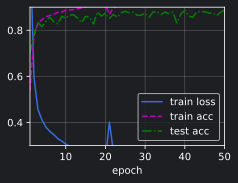

In [5]:
num_epochs, lr, batch_size = 50, 0.5, 256
loss1 = nn.CrossEntropyLoss(reduction='none')
train_iter, test_iter = d2l.load_data_fashion_mnist(batch_size, root='../../data')

net1 = nn.Sequential(
    nn.Flatten(),
    nn.Linear(784, 256),
    nn.ReLU(),
    # Add a dropout layer after the first fully connected layer
    # nn.Dropout(dropout1),
    nn.Linear(256, 256),
    nn.ReLU(),
    # Add a dropout layer after the second fully connected layer
    # nn.Dropout(dropout2),
    nn.Linear(256, 10),
)

def init_weights1(m):
    if isinstance(m, nn.Linear):
        nn.init.normal_(m.weight, std=0.01)

net1.apply(init_weights1)


trainer1 = torch.optim.SGD(net1.parameters(), lr=lr)
d2l.train_ch3(net1, train_iter, test_iter, loss1, num_epochs, trainer1)

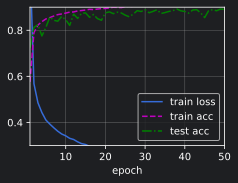

In [7]:
num_epochs, lr, batch_size = 50, 0.5, 256
dropout1, dropout2= 0.2, 0.5
loss2 = nn.CrossEntropyLoss(reduction='none')
train_iter, test_iter = d2l.load_data_fashion_mnist(batch_size, root='../../data')

net2 = nn.Sequential(
    nn.Flatten(),
    nn.Linear(784, 256),
    nn.ReLU(),
    # Add a dropout layer after the first fully connected layer
    nn.Dropout(dropout1),
    nn.Linear(256, 256),
    nn.ReLU(),
    # Add a dropout layer after the second fully connected layer
    nn.Dropout(dropout2),
    nn.Linear(256, 10),
)

def init_weights2(m):
    if isinstance(m, nn.Linear):
        nn.init.normal_(m.weight, std=0.01)

net2.apply(init_weights1)


trainer2 = torch.optim.SGD(net2.parameters(), lr=lr)
d2l.train_ch3(net2, train_iter, test_iter, loss2, num_epochs, trainer2)

# **Question 4.6.3**
**When using or not using dropout, what is the variance of the activation values in each hidden layer? Plot a curve to show how the variance of the activation values in each hidden layer of these two models changes over time.**

Using the temporary retreat method, each intermediate active value $h$ is replaced with a temporary retreat probability $p$ by the random variable $h'$, as shown below:
$$
h'=
\begin{cases}
0 & The \ probability \ is \ p \\
\frac{h}{1-p} & other \ cases
\end{cases}
$$
Its expected value remains the same, that is: $E[h']=h$. The variance is: $D(h')=E((h'-E(h'))^2)=E(h'^2)-E^2(h')=\frac{h^2}{(1-p)}-h$

In [8]:
def dropout_layer(X, dropout):
    assert 0 <= dropout <= 1
    # In this case, all elements are discarded.
    if dropout == 1:
        return torch.zeros_like(X)
    # In this case, all elements are retained.
    if dropout == 0:
        return X
    mask = (torch.rand(X.shape) > dropout).float()
    return mask * X / (1.0 - dropout)

Text(0, 0.5, 'var')

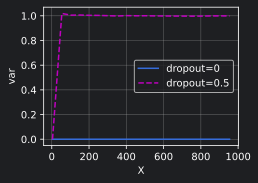

In [9]:
dropout0,dropout0d5,var_dropout0d5,var_dropout0=dropout_layer(torch.ones(1,dtype = torch.float32), 0),dropout_layer(torch.ones(1,dtype = torch.float32), 0.5),torch.empty(1),torch.empty(1)

for _ in range(1000):
    dropout0d5=torch.cat([dropout0d5,dropout_layer(torch.ones(1,dtype = torch.float32), 0.5)])
    dropout0=torch.cat([dropout0,dropout_layer(torch.ones(1,dtype = torch.float32), 0)])

    var_dropout0d5=torch.cat([var_dropout0d5,torch.var(dropout0d5).reshape(1)])
    var_dropout0=torch.cat([var_dropout0,torch.var(dropout0).reshape(1)])

d2l.plot(torch.arange(2,1003)[2:-1:50], [var_dropout0.detach()[2:-1:50],var_dropout0d5.detach()[2:-1:50]],
         legend=['dropout=0','dropout=0.5'])
d2l.plt.xlabel("X")
d2l.plt.ylabel("var")

# **Question 4.6.4**
**Why is the rollback method usually not used during testing?**

We use dropout during training to prevent the model from overfitting and to improve the network's generalization ability, but during testing, we want to use all the parameters, because reducing parameters can actually affect the network's stability.

# **Question 4.6.5**
**Using the model in this section as an example, compare the effects of using dropout and weight decay. What happens if you use both dropout and weight decay at the same time? Are the results cumulative? Does the benefit decrease (or get worse)? Do they cancel each other out?**

Using both dropout and weight decay at the same time works better than using just dropout or just weight decay. Dropout and weight decay prevent the model from overfitting in different ways, so using them together has a cumulative effect.

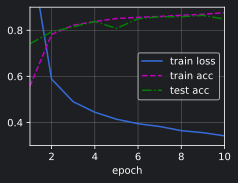

In [10]:
# use dropout but not weight decay
num_epochs, lr, batch_size = 10, 0.5, 256
dropout1, dropout2= 0.2, 0.5
loss = nn.CrossEntropyLoss(reduction='none')
train_iter, test_iter = d2l.load_data_fashion_mnist(batch_size, root='../../data')

net = nn.Sequential(
    nn.Flatten(),
    nn.Linear(784, 256),
    nn.ReLU(),
    # Add a dropout layer after the first fully connected layer
    nn.Dropout(dropout1),
    nn.Linear(256, 256),
    nn.ReLU(),
    # Add a dropout layer after the second fully connected layer
    nn.Dropout(dropout2),
    nn.Linear(256, 10),
)

def init_weights(m):
    if isinstance(m, nn.Linear):
        nn.init.normal_(m.weight, std=0.01)

net.apply(init_weights)


trainer = torch.optim.SGD(net.parameters(), lr=lr)
d2l.train_ch3(net, train_iter, test_iter, loss, num_epochs, trainer)

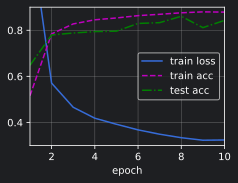

In [11]:
# use weight decay but not dropout
num_epochs, lr, batch_size = 10, 0.5, 256
# dropout1, dropout2= 0.2, 0.5
loss = nn.CrossEntropyLoss(reduction='none')
train_iter, test_iter = d2l.load_data_fashion_mnist(batch_size, root='../../data')

net = nn.Sequential(
    nn.Flatten(),
    nn.Linear(784, 256),
    nn.ReLU(),
    # Add a dropout layer after the first fully connected layer
    # nn.Dropout(dropout1),
    nn.Linear(256, 256),
    nn.ReLU(),
    # Add a dropout layer after the second fully connected layer
    # nn.Dropout(dropout2),
    nn.Linear(256, 10),
)

def init_weights(m):
    if isinstance(m, nn.Linear):
        nn.init.normal_(m.weight, std=0.01)

net.apply(init_weights)

params = [
    {'params': [p for n, p in net.named_parameters() if 'weight' in n], 'weight_decay': 1e-4},
    {'params': [p for n, p in net.named_parameters() if 'bias'   in n], 'weight_decay': 0.0},
]

trainer = torch.optim.SGD(params, lr=lr)
d2l.train_ch3(net, train_iter, test_iter, loss, num_epochs, trainer)

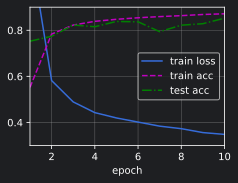

In [12]:
# use both weight decay and dropout
num_epochs, lr, batch_size = 10, 0.5, 256
dropout1, dropout2= 0.2, 0.5
loss = nn.CrossEntropyLoss(reduction='none')
train_iter, test_iter = d2l.load_data_fashion_mnist(batch_size, root='../../data')

net = nn.Sequential(
    nn.Flatten(),
    nn.Linear(784, 256),
    nn.ReLU(),
    # Add a dropout layer after the first fully connected layer
    nn.Dropout(dropout1),
    nn.Linear(256, 256),
    nn.ReLU(),
    # Add a dropout layer after the second fully connected layer
    nn.Dropout(dropout2),
    nn.Linear(256, 10),
)

def init_weights(m):
    if isinstance(m, nn.Linear):
        nn.init.normal_(m.weight, std=0.01)

net.apply(init_weights)

params = [
    {'params': [p for n, p in net.named_parameters() if 'weight' in n], 'weight_decay': 1e-4},
    {'params': [p for n, p in net.named_parameters() if 'bias'   in n], 'weight_decay': 0.0},
]

trainer = torch.optim.SGD(params, lr=lr)
d2l.train_ch3(net, train_iter, test_iter, loss, num_epochs, trainer)

# **Question 4.6.6**
**What would happen if we applied dropout to the individual weights of a weight matrix instead of the activations?**

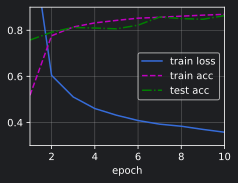

In [14]:
# use dropout but not weight decay
num_epochs, lr, batch_size = 10, 0.5, 256
dropout1, dropout2, dropout3 = 0.2, 0.5, 0.7
loss = nn.CrossEntropyLoss(reduction='none')
train_iter, test_iter = d2l.load_data_fashion_mnist(batch_size, root='../../data')

net = nn.Sequential(
    nn.Flatten(),
    nn.Linear(784, 256),
    # Add a dropout layer after the first linear layer
    nn.Dropout(dropout1),
    nn.ReLU(),

    nn.Linear(256, 256),
    # Add a dropout layer after the second fully connected layer
    nn.Dropout(dropout2),
    nn.ReLU(),
    nn.Linear(256, 10),

    # Add a dropout layer after the third fully connected layer
    # nn.Dropout(dropout3),
)

def init_weights(m):
    if isinstance(m, nn.Linear):
        nn.init.normal_(m.weight, std=0.01)

net.apply(init_weights)


trainer = torch.optim.SGD(net.parameters(), lr=lr)
d2l.train_ch3(net, train_iter, test_iter, loss, num_epochs, trainer)

# **Question 4.6.7**
**Invent another technique for injecting random noise at each layer, which is different from the standard dropout method. Try to develop a method that performs better than dropout on the Fashion-MNIST dataset (for a fixed architecture).**

In [15]:
def noise_layer(X, rate=0.1):
    return X+rate*torch.rand(X.shape)

In [1]:
class Net4_6_8(nn.Module):
    def __init__(self, num_inputs, num_outputs, num_hiddens1, num_hiddens2,
                 is_training = True):
        super(Net4_6_8, self).__init__()
        self.num_inputs = num_inputs
        self.training = is_training
        self.lin1 = nn.Linear(num_inputs, num_hiddens1)
        self.lin2 = nn.Linear(num_hiddens1, num_hiddens2)
        self.lin3 = nn.Linear(num_hiddens2, num_outputs)
        self.relu = nn.ReLU()

    def forward(self, X):
        H1 = self.relu(self.lin1(X.reshape((-1, self.num_inputs))))
        # noise is only used when training the model
        if self.training:
            H1 = noise_layer(H1)
        H2 = self.relu(self.lin2(H1))
        if self.training:
            H2 = noise_layer(H2)
        out = self.lin3(H2)
        return out

num_inputs, num_outputs, num_hiddens1, num_hiddens2 = 784, 10, 256, 256
net = Net4_6_8(num_inputs, num_outputs, num_hiddens1, num_hiddens2)
num_epochs, lr, batch_size = 10, 0.5, 256
loss = nn.CrossEntropyLoss(reduction='none')
train_iter, test_iter = d2l.load_data_fashion_mnist(batch_size, root='../../data')
trainer = torch.optim.SGD(net.parameters(), lr=lr)
d2l.train_ch3(net, train_iter, test_iter, loss, num_epochs, trainer, y_lim=[-0.2, 1.2])

NameError: name 'nn' is not defined